In [12]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
import rainflow

## Step 1: Extract and reshape the test data

In [2]:
df_test = loadmat(r"C:\Users\natal\Downloads\NREL_Testset10000.mat")


In [3]:
Hs = df_test['Hs'].flatten()
Tp = df_test['Tp'].flatten()
Vw = df_test['Vw_mean'].flatten()

RPM = df_test['Rpm_mean'].flatten()
Pitch = df_test['Pitch_mean'].flatten()

Mxx = df_test['Mxx']
Myy = df_test['Myy']

In [4]:
n_sim = len(Hs)

Mxx = Mxx.reshape(n_sim, 30000)
Myy = Myy.reshape(n_sim, 30000)

In [5]:
print(Mxx.shape)
print(Myy.shape)

(9960, 30000)
(9960, 30000)


## Step 2: Compute the resultant moment

In [6]:
Mres = np.sqrt(Mxx**2 + Myy**2)

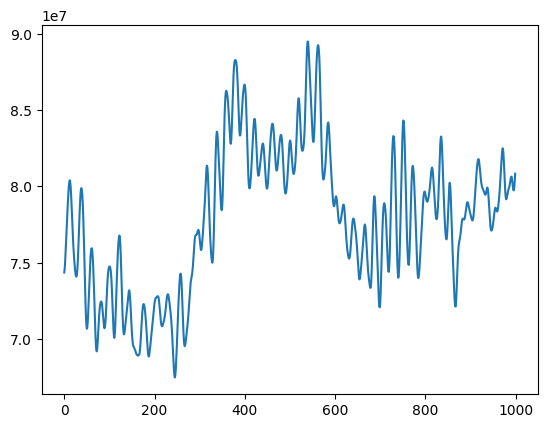

In [9]:
plt.plot(Mres[0,:1000])
plt.show()

## Step 3: Use rainflow (for ONE simulation)

In [13]:
cycles = rainflow.extract_cycles(Mres[0])

In [14]:
list(cycles)[:10]

[(np.float64(6037274.6636098325), np.float64(77379285.52693565), 0.5, 0, 12),
 (np.float64(5791088.524705693), np.float64(76987995.9696624), 1.0, 27, 38),
 (np.float64(5275139.509107813), np.float64(73313198.51015821), 1.0, 50, 61),
 (np.float64(1753407.407634139), np.float64(71585416.74542178), 1.0, 82, 89),
 (np.float64(4673463.18869859), np.float64(72419646.06000204), 1.0, 100, 111),
 (np.float64(2884004.469474122), np.float64(71752992.12963188), 1.0, 132, 144),
 (np.float64(7583436.578298867), np.float64(72989975.49263686), 1.0, 72, 122),
 (np.float64(3375634.7455520034),
  np.float64(70606276.43854444),
  1.0,
  163,
  176),
 (np.float64(1965604.5588126928),
  np.float64(71823983.80540857),
  1.0,
  207,
  217),
 (np.float64(4073404.0804494917),
  np.float64(70894231.04032756),
  1.0,
  187,
  230)]

## Step 5: Compute DEL (for ONE simulation)
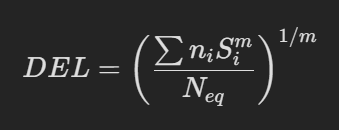

In [15]:
m = 4
Neq = 1e7

In [16]:
damage_sum = 0

for rng, mean, count, i_start, i_end in rainflow.extract_cycles(Mres[0]):

    damage_sum += count * rng**m

DEL = (damage_sum / Neq)**(1/m)

## Step 6: Create a processing function

In [17]:
def calculate_del(signal,
                  m=4,
                  Neq=1e7):

    damage_sum = 0

    for rng, mean, count, _, _ in rainflow.extract_cycles(signal):

        damage_sum += count * rng**m

    return (damage_sum / Neq)**(1/m)

In [18]:
del1 = calculate_del(Mres[0])
print(del1)

1460472.275131001


## Step 7: Process a subset first

In [19]:
DEL = np.zeros(100)

for i in range(100):

    DEL[i] = calculate_del(Mres[i])

    if i % 10 == 0:
        print(i)

0
10
20
30
40
50
60
70
80
90


(array([ 2.,  9., 24., 12.,  9., 14.,  4.,  7., 12.,  7.]),
 array([ 182099.1989989 ,  419170.33977889,  656241.48055888,
         893312.62133888, 1130383.76211887, 1367454.90289886,
        1604526.04367885, 1841597.18445885, 2078668.32523884,
        2315739.46601883, 2552810.60679883]),
 <BarContainer object of 10 artists>)

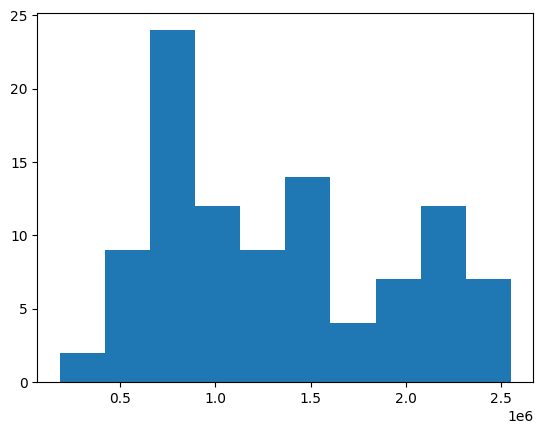

In [20]:
plt.hist(DEL)

## Step 9: Build final dataframe

In [22]:
print(len(Hs))
print(len(Tp))
print(len(Vw))
print(len(RPM))
print(len(Pitch))
print(len(DEL))

9960
9960
9960
9960
9960
100


In [24]:
df_final = pd.DataFrame({
    "Hs": Hs[:100],
    "Tp": Tp[:100],
    "Vw_mean": Vw[:100],
    "RPM": RPM[:100],
    "Pitch": Pitch[:100],
    "DEL": DEL
})

In [26]:
df_final.head(10)

,Hs,Tp,Vw_mean,RPM,Pitch,DEL
0,1.248500,4.757716,9.203143,9.972552,0.019171,1.460472e+06
1,1.574769,6.303943,11.370682,11.694177,1.296207,1.733923e+06
2,0.895745,5.364305,11.460520,11.757063,1.184234,1.831648e+06
3,0.638518,7.412787,6.598440,8.256958,0.000000,8.610574e+05
4,2.740453,5.828636,15.811478,12.093967,10.479204,2.552811e+06
5,1.199323,6.809924,5.517438,7.732617,0.000000,9.316728e+05
6,1.511732,4.932481,9.366478,10.301602,0.122761,1.583344e+06
7,0.591596,5.226274,4.886117,7.305118,0.000000,5.887586e+05
8,0.267179,5.955356,2.928628,4.242490,0.000000,5.623319e+05
9,1.608027,7.488627,8.962030,9.913233,0.000000,1.469135e+06


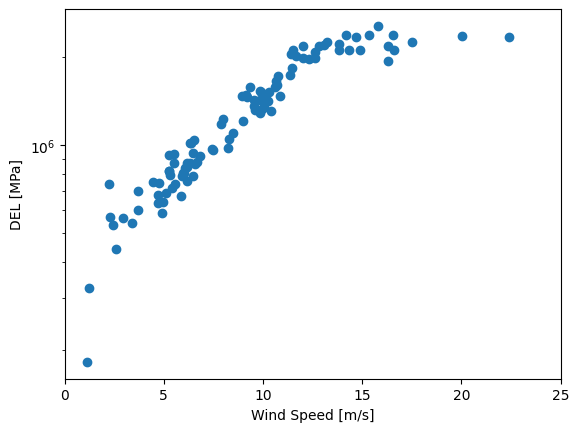

In [28]:
plt.scatter(df_final["Vw_mean"], df_final["DEL"])
plt.xticks(np.arange(0, 30, 5))
plt.xlabel("Wind Speed [m/s]")
plt.ylabel("DEL [MPa]")
plt.yscale("log")

In [23]:
# df_final = pd.DataFrame({
#     "Hs": Hs,
#     "Tp": Tp,
#     "Vw_mean": Vw,
#     "RPM": RPM,
#     "Pitch": Pitch,
#     "DEL": DEL
# })